# C1T4: Feedback Signals (100k Window)

## Libraries

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

orders = ["IDP", "IPD", "DIP", "DPI", "PID", "PDI"]

## LRU Data

In [8]:
chirper = pd.read_csv("../data/chirper_LRU_100k.csv").set_index("phase")
mcf = pd.read_csv("../data/mcf_LRU_100k.csv").set_index("phase")
omnetpp = pd.read_csv("../data/omnetpp_LRU_100k.csv").set_index("phase")
tomcat = pd.read_csv("../data/tomcat_LRU_100k.csv").set_index("phase")
tpcc = pd.read_csv("../data/tpcc_LRU_100k.csv").set_index("phase")

workloads = {"chirper": chirper, "mcf": mcf, "omnetpp": omnetpp,
             "tomcat": tomcat, "tpcc": tpcc}


## Fixed Priority Data

In [9]:
fixed_cycles = {}

for workload in workloads:
    cycles = pd.DataFrame()
    for order in orders:
        run = pd.read_csv(f"../data/{workload}_{order}_100k.csv").set_index("phase")
        cycles[order] = run["cycles"]
    fixed_cycles[workload] = cycles

## Feedback Signals

In [10]:
signals = {}

for workload, baseline in workloads.items():
    df = baseline[["stlb_mpki", "l1i_mpki", "l1d_mpki"]].copy()
    df.columns = ["STLB MPKI", "L1I MPKI", "L1D MPKI"]

    for name, prefix in [("I", "instruction"), ("D", "data"), ("P", "pte")]:
        hits = baseline[prefix + "_hits"]
        misses = baseline[prefix + "_misses"]
        accesses = hits + misses
        df[name + " L2 MPKI"] = misses * 1000 / baseline["instructions"]
        df[name + " hit fraction"] = hits / accesses.replace(0, float("nan"))
        df[name + " traffic share"] = accesses / baseline["accesses"].replace(0, float("nan"))

    signals[workload] = df


## Priority Comparisons

In [11]:
comparisons = {
    "P>D, I first": ("IPD", "IDP"),
    "P>D, I last": ("PDI", "DPI"),
    "I>D, P first": ("PID", "PDI"),
    "I>D, P last": ("IDP", "DIP"),
    "P>I, D first": ("DPI", "DIP"),
    "P>I, D last": ("PID", "IPD")
}
benefits = {}

for workload in workloads:
    cycles = fixed_cycles[workload]
    df = pd.DataFrame(index=cycles.index)
    for name, (first, second) in comparisons.items():
        df[name] = (cycles[second] / cycles[first] - 1) * 100
    benefits[workload] = df


## Pearson Heatmaps


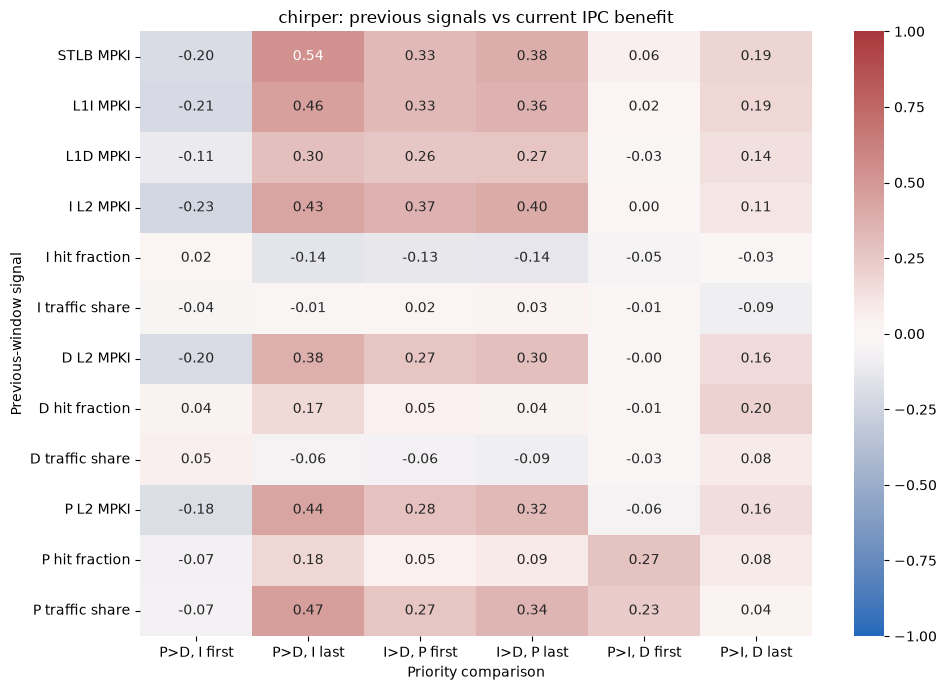

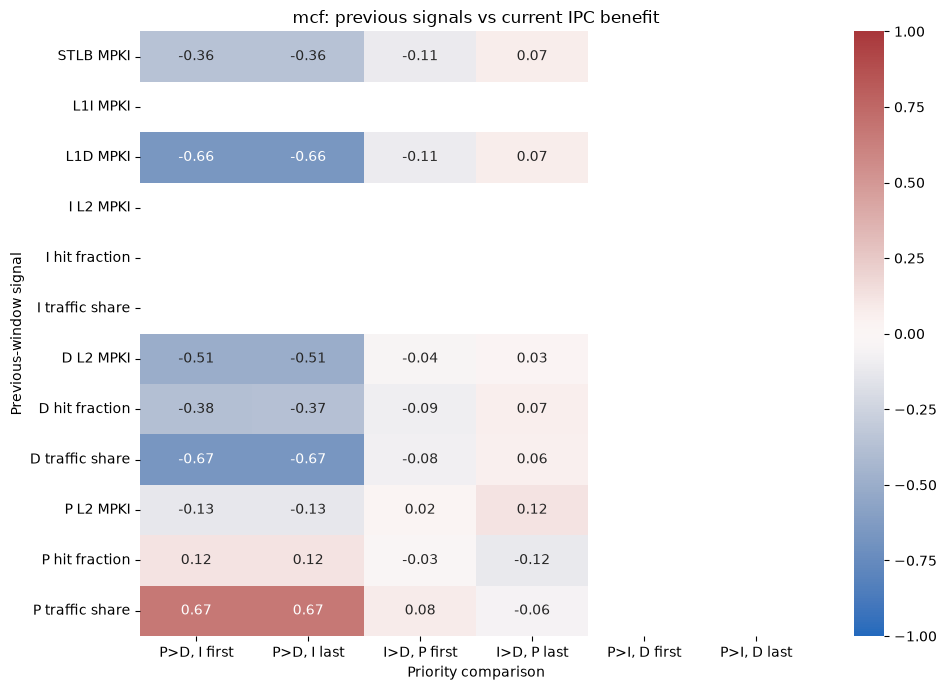

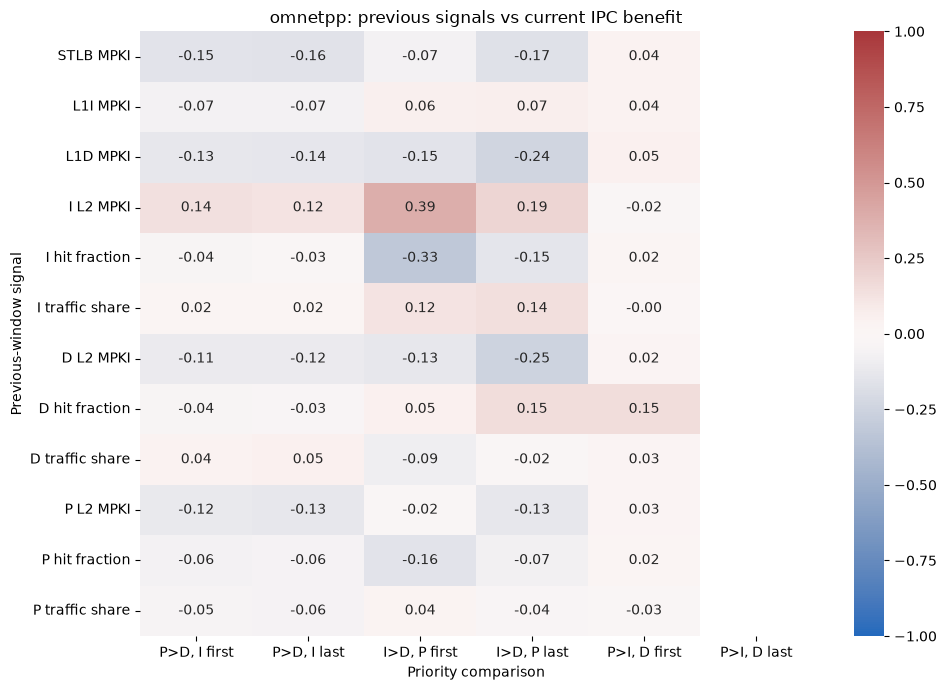

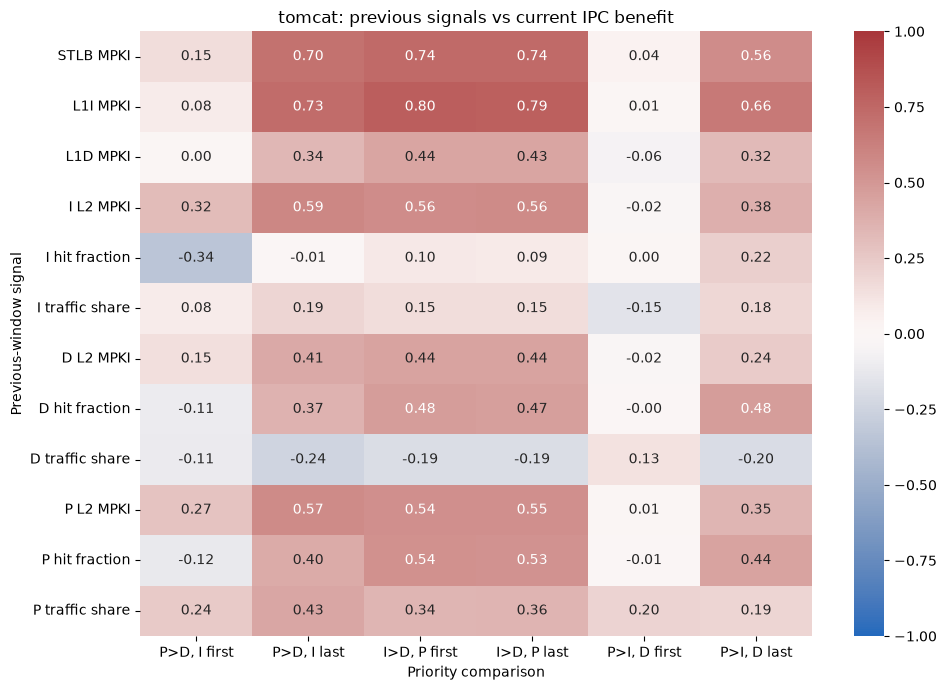

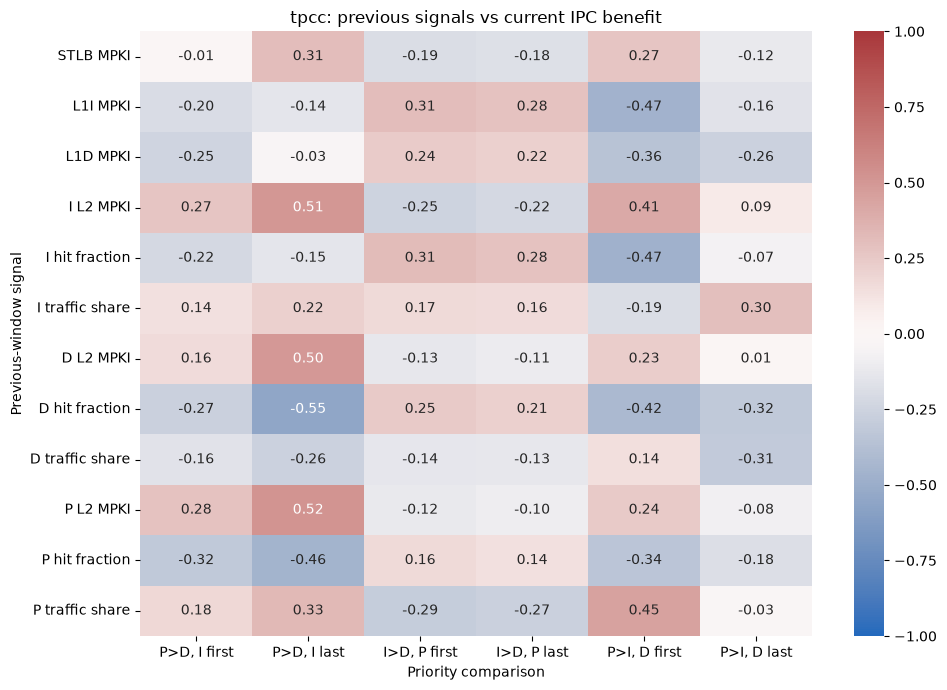

In [12]:
pearson = {}

for workload in workloads:
    previous = signals[workload].shift(1)
    table = previous.join(benefits[workload])
    pearson[workload] = table.corr(method="pearson").loc[previous.columns, list(comparisons)]

    plt.figure(figsize=(10, 7))
    sns.heatmap(pearson[workload], annot=True, fmt=".2f",
                cmap="vlag", center=0, vmin=-1, vmax=1)
    plt.title(f"{workload}: previous signals vs current IPC benefit")
    plt.xlabel("Priority comparison")
    plt.ylabel("Previous-window signal")
    plt.tight_layout()
    plt.savefig(f"../results/{workload}_feedback_pearson.png", dpi=200)
    plt.show()
